<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">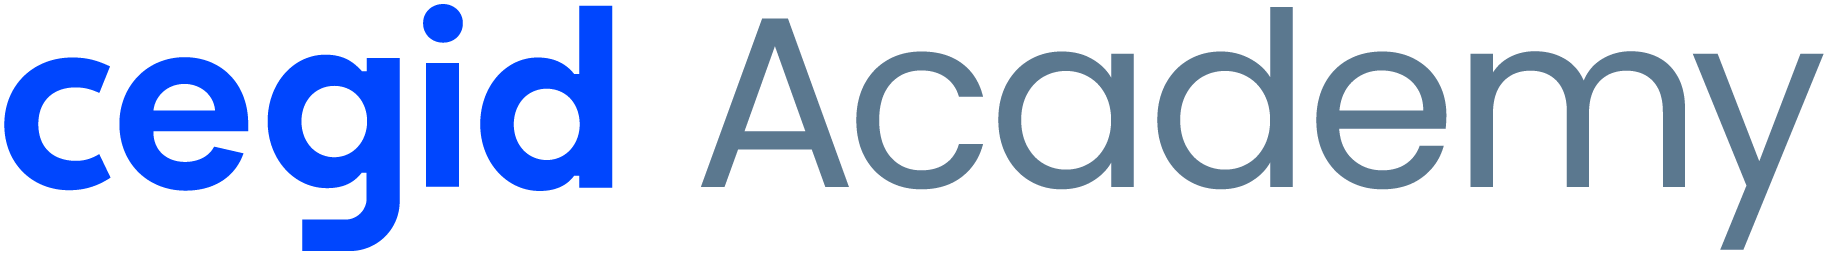<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 4 &middot; Modelação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Modeling</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M4 · M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| Projeto | Previsão da intenção de mudança de emprego |
| Grupo | Não indicado nos ficheiros fornecidos |
| Formandos | Não indicados nos ficheiros fornecidos |
| Data da revisão | 14/10/2026 |
| Dataset | `Data/input/Dados_RH_Mudanca_Emprego.csv` |

> **Versão atualizada após a entrega original.** A árvore de decisão e o Random Forest foram acrescentados em revisões posteriores. A escolha entre os três algoritmos usa apenas validação cruzada no treino.


<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Treinar, afinar e comparar modelos de forma <b>justa</b> — mesma divisão treino/teste, mesmo pré-processamento, mesmas métricas — para responder à pergunta central da modelação:<br><br><b>Qual o modelo que generaliza melhor para dados novos?</b></div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Comparem <b>vários modelos</b> (pelo menos 3 + baseline). Centrar toda a modelação num único algoritmo não permite justificar a escolha final. Mantenham apenas as secções <b>[Classificação]</b>, <b>[Regressão]</b> ou <b>[Clustering]</b> que se aplicam ao vosso problema.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">O teste não serve para escolher</div>A escolha de modelos, hiperparâmetros, variáveis e limiares faz-se com a <b>validação cruzada no treino</b>. As métricas no teste que aparecem nas secções 2 e 3 servem apenas de diagnóstico: se escolherem o modelo (ou voltarem a afinar) porque teve melhor resultado no teste, o teste passa a funcionar como conjunto de validação e o resultado final fica <b>otimista</b> — deixa de ser uma estimativa honesta do desempenho em dados novos.<ul style="margin:4px 0 2px 0;"><li>decidir sempre pela média da CV (secção 6);</li><li>o <code>GridSearchCV</code> / <code>RandomizedSearchCV</code> recebe apenas <code>X_train</code> e <code>y_train</code>;</li><li>o pré-processamento fica <b>dentro</b> do Pipeline, para ser reajustado em cada fold;</li><li>se, depois de verem o teste, voltarem às Fases 3/4 para mudar alguma coisa, registem-no na Fase 5 como limitação.</li></ul></div>

**Índice**

0. Configuração · 1. Estratégia · 2. Classificação · 5. Ajuste de hiperparâmetros · 6. Seleção · 7. Teste final · 8. Exportação · 9. Síntese

Mantém-se a numeração do template. Regressão e clustering não se aplicam ao alvo binário e foram retirados.

### 0. Configuração
<hr>

**0.1 Bibliotecas**

Usamos `DummyClassifier`, `LogisticRegression` e `DecisionTreeClassifier` e `RandomForestClassifier`, com `Pipeline`, preparação dentro de cada fold e `StratifiedKFold`.


In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier
from preparacao_rh import preparar_registos


**0.2 Carregar a configuração**
- Ler `Data/output/config_projeto.json` e criar as variáveis `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `NUM_COLS`, `CAT_COLS`, `FEATURES = NUM_COLS + CAT_COLS`, `RANDOM_STATE`.

In [2]:
config = json.loads(Path('Data/output/config_projeto.json').read_text(encoding='utf-8'))
PROJETO = config['PROJETO']
TARGET = config['TARGET']
FEATURES = config['RAW_FEATURES']
NUM_COLS = config['NUM_COLS']
CAT_COLS = config['CAT_COLS']
RANDOM_STATE = config['RANDOM_STATE']
LIMIAR = config['LIMIAR']
SAIDA = Path('Data/output')
MODELOS = Path('Data/models')
ANALYTICS = Path('Data/analytics')


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
for pasta in [SAIDA, MODELOS, ANALYTICS]:
    pasta.mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    plt.tight_layout()
    plt.savefig(ANALYTICS / nome, dpi=150)
    plt.show()


**0.4 Carregar os dados da Fase 3**
- Classificação/regressão: ler `<PROJETO>_train.csv` e `<PROJETO>_test.csv` → `X_train`, `y_train`, `X_test`, `y_test`.
- Clustering: ler `<PROJETO>_dataset_clustering.csv` → `X`.

In [4]:
treino = pd.read_csv(SAIDA / f'{PROJETO}_train_raw.csv')
teste = pd.read_csv(SAIDA / f'{PROJETO}_test_raw.csv')
X_train = treino[FEATURES]
y_train = treino[TARGET].astype(int)
X_test = teste[FEATURES]
y_test = teste[TARGET].astype(int)
print('Treino:', X_train.shape, '| teste:', X_test.shape)


Treino: (15326, 12) | teste: (3832, 12)


**0.5 Pipeline de preparação + modelo (M4)**
- Criar uma função que devolva o `ColumnTransformer` da Fase 3 (com ou sem scaling) e outra que devolva `Pipeline([("prep", prep), ("clf", modelo)])` (`"reg"` em regressão).

In [5]:
# A preparação e o modelo ficam juntos para prever novos registos.
prep = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), NUM_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Desconhecido')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CAT_COLS)
])

def criar_pipeline(classificador):
    return Pipeline([
        ('limpeza', FunctionTransformer(preparar_registos, validate=False)),
        ('prep', prep),
        ('clf', classificador)
    ])


### 1. Estratégia de modelação

O alvo é binário: Sim (1) ou Não (0). Comparamos um baseline que prevê a classe maioritária com três algoritmos de classificação: regressão logística, árvore de decisão e Random Forest. O F1 da classe Sim nos mesmos cinco folds estratificados do treino determina o vencedor. Todos usam o mesmo pipeline de preparação e o limiar 0,50.


**Resposta:** Executamos o baseline e três modelos com parâmetros fixos. A árvore usa profundidade máxima 5 e pelo menos 50 exemplos por folha; a floresta usa 100 árvores, profundidade máxima 8 e pelo menos 20 exemplos por folha. Não fazemos GridSearchCV nem RandomizedSearchCV.


> **Contexto das aulas:** a regressão logística oferece uma referência linear, a árvore permite divisões interpretáveis e a floresta combina várias árvores. O `DummyClassifier` serve de baseline e não conta como um dos três modelos.


<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">CLASSIFICAÇÃO</div>

### 2. Classificação: treino e validação cruzada

O teste permanece reservado até à escolha final. Comparamos modelos nos mesmos cinco folds do treino.

**2.1 [Classificação] Definições**
- Métrica principal (ex.: `"f1"`; nas aulas `"accuracy"`; em multiclasse usar `"f1_macro"` ou `"f1_weighted"` e `"roc_auc_ovr"`), `StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`.
- (Sugestão) uma função que calcule accuracy, precision, recall, F1 e ROC-AUC para um modelo e um conjunto de dados.

In [6]:
# F1 equilibra precision e recall da classe "Sim".
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def calcular_metricas(real, previsto, probabilidade):
    return {
        'accuracy': metrics.accuracy_score(real, previsto),
        'precision': metrics.precision_score(real, previsto, zero_division=0),
        'recall': metrics.recall_score(real, previsto, zero_division=0),
        'f1': metrics.f1_score(real, previsto, zero_division=0),
        'roc_auc': metrics.roc_auc_score(real, probabilidade),
        'average_precision': metrics.average_precision_score(real, probabilidade)
    }


**2.2 Comparação no treino**

O baseline e os três classificadores são avaliados nos mesmos cinco folds, com F1 da classe Sim. O teste não participa na escolha.


In [7]:
# Um baseline e três modelos preditivos, com parâmetros fixados antes da comparação.
baseline = criar_pipeline(DummyClassifier(strategy='most_frequent'))
logistica = criar_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
arvore = criar_pipeline(DecisionTreeClassifier(
    max_depth=5, min_samples_leaf=50, class_weight='balanced',
    random_state=RANDOM_STATE
))
floresta = criar_pipeline(RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_leaf=20,
    class_weight='balanced_subsample', random_state=RANDOM_STATE,
    n_jobs=1
))
folds_baseline = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1')
folds_logistica = cross_val_score(logistica, X_train, y_train, cv=cv, scoring='f1')
folds_arvore = cross_val_score(arvore, X_train, y_train, cv=cv, scoring='f1')
folds_floresta = cross_val_score(floresta, X_train, y_train, cv=cv, scoring='f1')
comparacao = pd.DataFrame({
    'modelo': ['Baseline', 'Regressão logística', 'Árvore de decisão', 'Random Forest'],
    'f1_cv': [folds_baseline.mean(), folds_logistica.mean(), folds_arvore.mean(), folds_floresta.mean()],
    'f1_std': [folds_baseline.std(), folds_logistica.std(), folds_arvore.std(), folds_floresta.std()]
}).set_index('modelo')
display(comparacao.round(3))


,f1_cv,f1_std
modelo,,
Baseline,0.000,0.000
Regressão logística,0.466,0.010
Árvore de decisão,0.611,0.010
Random Forest,0.618,0.008


**Resposta:** A tabela apresenta o F1 médio e o desvio nos cinco folds de treino. O baseline prevê sempre Não e tem F1 igual a zero para a classe Sim. A comparação contém três modelos preditivos além desta referência.


**2.3 Gráfico do F1 na validação cruzada**


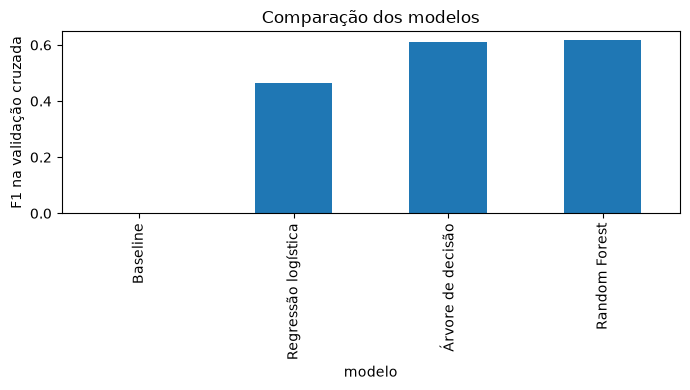

In [8]:
comparacao['f1_cv'].plot.bar(figsize=(7, 4))
plt.ylabel('F1 na validação cruzada')
plt.title('Comparação dos modelos')
guardar_figura('04_treino_validacao.png')


**Resposta:** As barras mostram o F1 médio de validação cruzada dos quatro candidatos (três modelos e baseline). Não são resultados do teste.


#### 2.4 Validação cruzada (M5)

Uma única divisão treino/teste depende da amostra que calhou. O **K-Fold** divide em K partes, treina em K−1 e testa na restante, K vezes; em classificação usa-se `StratifiedKFold`. Comparamos pela **média** (desempenho) e pelo **desvio padrão** (estabilidade).

Aqui a validação cruzada é feita **só com o treino** — o teste fica reservado para a avaliação final.

**2.4 [Classificação] Validação cruzada (M5)**
- `cross_val_score` com a `StratifiedKFold`, **só no treino**, para cada modelo: média ± desvio.
- Boxplot dos scores por fold.

In [9]:
scores_folds = pd.DataFrame({
    'Baseline': folds_baseline,
    'Regressão logística': folds_logistica,
    'Árvore de decisão': folds_arvore,
    'Random Forest': folds_floresta
})
display(scores_folds.round(3))


,Baseline,Regressão logística,Árvore de decisão,Random Forest
0,0.0,0.466,0.609,0.622
1,0.0,0.452,0.612,0.616
2,0.0,0.471,0.610,0.613
3,0.0,0.482,0.628,0.631
4,0.0,0.458,0.596,0.607


**Resposta:**

A média resume o desempenho nos cinco folds e o desvio mede a variação entre eles. Um modelo constante pode ter baixo desvio e ser inútil, como o baseline com F1 zero. Por isso, desempenho e estabilidade devem ser lidos em conjunto. Ainda não comparamos com o teste.

### 5. Parâmetros fixos, sem pesquisa

Para manter a experiência simples, comparamos parâmetros previamente fixados, sem pesquisa em grelha ou aleatória. A árvore limita a profundidade a 5 e exige 50 exemplos por folha; o Random Forest usa 100 árvores, profundidade máxima 8, pelo menos 20 exemplos por folha e pesos equilibrados por árvore. Assim, a comparação não constitui uma otimização exaustiva.


#### 5.1 Pesquisa em grelha não realizada


Comparamos os três algoritmos com parâmetros fixos. Não executámos `GridSearchCV`; por isso, não há `best_params_` nem pontuação de grelha a reportar.


In [10]:
print('Sem GridSearchCV. Parâmetros da árvore:', arvore.named_steps['clf'].get_params()['max_depth'], 'de profundidade máxima e 50 exemplos por folha.')


Sem GridSearchCV. Parâmetros da árvore: 5 de profundidade máxima e 50 exemplos por folha.


**Resposta:** A comparação do notebook usa validação cruzada simples sobre o treino, sem ajuste sistemático de hiperparâmetros.


#### 5.2 Pesquisa aleatória não realizada


O Random Forest foi avaliado por validação cruzada nos mesmos cinco folds dos restantes modelos. Não executámos `RandomizedSearchCV`; os seus parâmetros foram fixados antes da comparação.


In [11]:
print('Random Forest:', floresta.named_steps['clf'].get_params()['n_estimators'], 'árvores; F1 CV médio:', round(folds_floresta.mean(), 3))


Random Forest: 100 árvores; F1 CV médio: 0.618


**Resposta:** O Random Forest é o terceiro modelo comparado, além da regressão logística e da árvore de decisão. Não há pesquisa aleatória de parâmetros nem seleção pelo teste.


#### 5.3 Curva de validação não realizada


<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>A curva de validação não foi dada em aula; usa apenas <code>cross_validate</code> (variante do <code>cross_val_score</code> que também devolve o score no treino). É opcional.</div>

A profundidade da árvore ficou fixa em 5; não se calculou uma curva de validação para outros valores.


In [12]:
print('Árvore avaliada com profundidade fixa:', arvore.named_steps['clf'].max_depth)


Árvore avaliada com profundidade fixa: 5


**Resposta:** Sem variar a profundidade, não podemos atribuir um ganho a uma pesquisa de parâmetros. A estabilidade observável nesta experiência é o desvio do F1 nos cinco folds.


<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">COMPARAÇÃO FINAL E ESCOLHA DO MODELO</div>

### 6. Comparação final e seleção

Escolhemos entre regressão logística, árvore de decisão e Random Forest pelo maior F1 médio nos mesmos cinco folds de treino. O baseline é a referência. O teste não determina o vencedor.


**6.1 Comparação por validação cruzada**

A tabela abaixo mostra os três modelos e o baseline efetivamente executados.


In [13]:
# A comparação final usa apenas os resultados calculados no treino.
display(comparacao.round(3))


,f1_cv,f1_std
modelo,,
Baseline,0.000,0.000
Regressão logística,0.466,0.010
Árvore de decisão,0.611,0.010
Random Forest,0.618,0.008


**Resposta:** O código escolhe automaticamente o maior F1 médio entre os três classificadores, sem consultar o teste. O desvio dos folds descreve a variação nesta validação.


**6.2 Escolher o modelo final**
- Guardar o nome do modelo escolhido e o respetivo pipeline em `modelo_final` (não pode ser o baseline).

In [14]:
candidatos = {
    'Regressão logística': logistica,
    'Árvore de decisão': arvore,
    'Random Forest': floresta
}
nome_final = comparacao.loc[list(candidatos), 'f1_cv'].idxmax()
modelo_final = candidatos[nome_final].fit(X_train, y_train)
print('Modelo final:', nome_final)
print('F1 médio na validação cruzada:', round(comparacao.loc[nome_final, 'f1_cv'], 3))


Modelo final: Random Forest
F1 médio na validação cruzada: 0.618


<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Se nenhum modelo supera <b>claramente</b> o baseline, isso também é um resultado: pode significar que as variáveis disponíveis têm pouca capacidade explicativa. Nesse caso, discutam-no na Fase 5 e voltem às Fases 2/3 (novas variáveis, outros dados) em vez de forçar um modelo.</div>

#### Justificação da escolha

Os três classificadores usam os mesmos cinco folds e o F1 da classe Sim. A regressão logística é linear, a árvore capta relações não lineares por divisões e o Random Forest agrega várias árvores. O nome do vencedor é calculado na tabela de validação cruzada; a interpretação e as métricas finais devem corresponder ao modelo realmente escolhido após a execução.


### 7. Avaliação detalhada do modelo final no teste (M5)
<hr>

- **Classificação:** matriz de confusão, `classification_report` (precision, recall e F1 por classe), curva ROC e AUC
- **Regressão:** real vs previsto, resíduos vs previsto, distribuição dos resíduos

**7.1 [Classificação] Matriz de confusão e classification report (M5)**
- `confusion_matrix` + `ConfusionMatrixDisplay` e `classification_report` do modelo final no teste.

In [15]:
prob_teste = modelo_final.predict_proba(X_test)[:, 1]
y_pred = (prob_teste >= LIMIAR).astype(int)
metricas_teste = calcular_metricas(y_test, y_pred, prob_teste)
prob_treino = modelo_final.predict_proba(X_train)[:, 1]
metricas_treino = calcular_metricas(
    y_train, (prob_treino >= LIMIAR).astype(int), prob_treino
)
display(pd.Series(metricas_teste, name='teste').round(3).to_frame())
print(metrics.classification_report(y_test, y_pred, zero_division=0))


,teste
accuracy,0.757
precision,0.509
recall,0.746
f1,0.605
roc_auc,0.785
average_precision,0.512


              precision    recall  f1-score   support

           0       0.90      0.76      0.82      2877
           1       0.51      0.75      0.60       955

    accuracy                           0.76      3832
   macro avg       0.70      0.75      0.71      3832
weighted avg       0.80      0.76      0.77      3832



**Resposta:**

A matriz e o relatório distinguem os erros nas duas classes. FP são alertas de mudança para candidatos cujo alvo é Não; FN são candidatos com alvo Sim que não foram detetados. O seu número e as consequências são discutidos no notebook 05. A intenção declarada não é uma saída efetiva da organização.

**7.2 [Classificação binária] Curva ROC e AUC (M5)**
- `predict_proba`, `roc_curve` e `roc_auc_score`; desenhar a curva com a diagonal de referência.

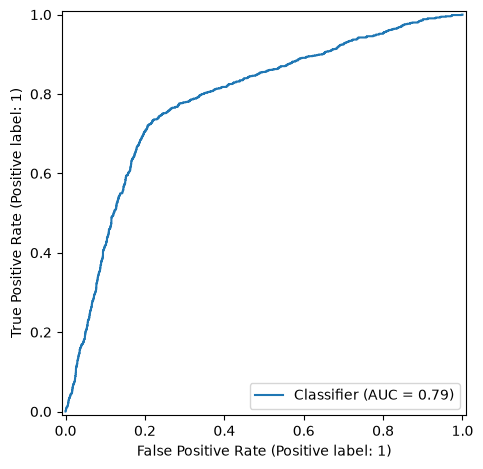

In [16]:
metrics.RocCurveDisplay.from_predictions(y_test, prob_teste)
guardar_figura('04_roc.png')


**Resposta:**

A ROC-AUC quantifica a capacidade de ordenar um candidato positivo acima de um negativo. Valores acima de 0,5 superam a ordenação aleatória; não representam a percentagem de previsões corretas nem comprovam a calibração das probabilidades. O valor medido está indicado na saída.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Matriz de confusão</b>: linhas = real, colunas = previsto; VP, VN, FP, FN.</li><li><b>Precision</b>: dos previstos positivos, quantos certos · <b>Recall</b>: dos positivos reais, quantos apanhados · <b>F1</b>: equilíbrio.</li><li><b>ROC</b>: quanto mais perto do canto superior esquerdo, melhor. AUC = 1 perfeito; 0,5 = acaso.</li></ul></div>

**7.3 (Complemento) Curva Precision-Recall**
- `PrecisionRecallDisplay.from_estimator`.

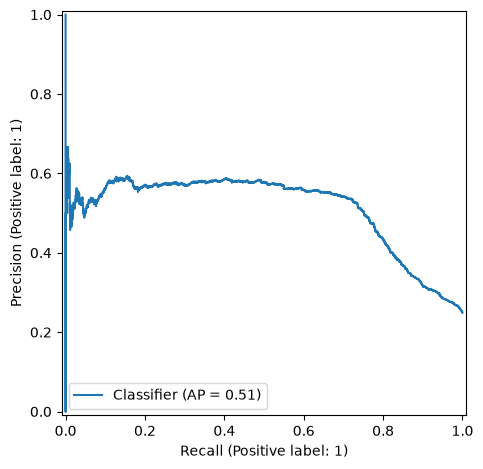

In [17]:
metrics.PrecisionRecallDisplay.from_predictions(y_test, prob_teste)
guardar_figura('04_precision_recall.png')


**Resposta:**

A curva mostra o compromisso entre detetar mais positivos e manter a precisão dos alertas. A linha horizontal é a prevalência de Sim. A Average Precision resume esta curva, sendo especialmente útil com classes desequilibradas. Alterar o limiar com base neste gráfico de teste invalidaria uma avaliação independente de um novo limiar.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li>Pontos próximos da diagonal → boas previsões; afastados → erros grandes em certas faixas.</li><li>Padrão curvo nos resíduos → não linearidade não captada.</li><li>Dispersão a aumentar com o valor previsto → o erro cresce com o valor (heterocedasticidade).</li></ul></div>

#### Análise dos resultados

O desempenho no teste é reportado depois de fixar o modelo, a preparação e o limiar. O afastamento face à CV é analisado no notebook 05. A exploração inicial do notebook 02 usou todo o CSV, incluindo o alvo; assim, a separação protege a seleção formal de modelos, mas não constitui uma validação externa totalmente intocada. Seriam necessários novos dados para confirmar os resultados fora desta amostra.

### 8. Guardar o modelo e os resultados (M5)
<hr>

Guarda-se o **pipeline completo** (preparação + modelo) com `joblib` — em produção basta carregá-lo e prever.

- `Data/models/<PROJETO>_modelo_final.joblib` — usado nas Fases 5 e 6
- `Data/models/<PROJETO>_modelo_final.json` — metadados (nome, hiperparâmetros, data)
- `Data/output/<PROJETO>_comparacao_modelos.csv` — tabela de comparação

**8. Guardar o modelo e os resultados (M5)** (necessário para os notebooks 05 e 06)
- `joblib.dump(modelo_final, "Data/models/<PROJETO>_modelo_final.joblib")`.
- Gravar `Data/models/<PROJETO>_modelo_final.json` com: `modelo` (nome), `problema`, `target`, `features`, `hiperparametros` e `data_treino`.
- Gravar a tabela de comparação em `Data/output/<PROJETO>_comparacao_modelos.csv`.
- Recarregar o modelo com `joblib.load` para confirmar.

In [18]:
# Guardar o pipeline escolhido e os resultados da versão atualizada.
joblib.dump(modelo_final, MODELOS / f'{PROJETO}_modelo_final.joblib')
metadados = {
    'versao': 'pos_entrega_tres_modelos_v3',
    'modelo': nome_final,
    'problema': 'classificacao',
    'target': TARGET,
    'features': FEATURES,
    'limiar': LIMIAR,
    'f1_cv': float(comparacao.loc[nome_final, 'f1_cv']),
    'f1_cv_std': float(comparacao.loc[nome_final, 'f1_std']),
    'metricas_treino': metricas_treino,
    'metricas_teste': metricas_teste
}
(MODELOS / f'{PROJETO}_modelo_final.json').write_text(
    json.dumps(metadados, ensure_ascii=False, indent=2), encoding='utf-8'
)
comparacao.to_csv(SAIDA / f'{PROJETO}_comparacao_modelos.csv')
scores_folds.to_csv(SAIDA / f'{PROJETO}_cv_folds_base.csv', index=False)
print('Modelo e resultados da versão atualizada guardados.')


Modelo e resultados da versão atualizada guardados.


### 9. Síntese da Fase de Modelação
<hr>

**Descrever:**
- Modelos testados (e baseline)
- Hiperparâmetros ajustados e método usado
- Melhor modelo e métricas obtidas (CV e teste)
- Limitações identificadas
- Próximos passos (se aplicável)

***Objetivo:*** documentar a modelação antes da avaliação de negócio.

**Resposta:** Foram comparados três modelos — regressão logística, árvore de decisão e Random Forest — além do baseline. A escolha do modelo final seguiu o F1 médio nos cinco folds do treino. Não houve pesquisa em grelha ou aleatória. O pipeline e as métricas são guardados para os notebooks 05 e 06.


<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><b>Antes de avançar:</b> confirmar que a tabela mostra quatro candidatos (três modelos e baseline), que o modelo escolhido coincide com o maior F1 médio e que o teste não foi usado para essa escolha.</div>


[← Fase 3: Preparação dos Dados](03_P_data_preparation.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 5: Avaliação →](05_P_evaluation.ipynb)
